In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path(r"D:\projects\f1-project")
laps = pd.read_csv(ROOT / "data/processed/laps_with_pit_flags_2023_2024_first5.csv")
pits = pd.read_csv(ROOT / "data/processed/pit_stops_2023_2024_first5.csv")

def to_seconds(text):
    """'1:39.019' -> 99.019. Works for 'm:ss.xxx', 'ss.xxx' and NaN."""
    total = 0.0
    for part in str(text).split(":"):
        total = total * 60 + float(part)
    return total

laps["lap_time_seconds"] = laps["lap_time"].apply(to_seconds)
laps["is_pit_lap"] = laps["is_pit_lap"].astype(bool)
print(laps.shape, pits.shape)
print(laps["lap_time_seconds"].describe())

(10050, 8) (374, 7)
count    10050.000000
mean       106.885037
std        109.822981
min         79.813000
25%         92.937250
50%         96.657500
75%        101.081750
max       2014.652000
Name: lap_time_seconds, dtype: float64


In [2]:
pits["duration_seconds"] = pits["duration"].apply(to_seconds)
print(pits["duration_seconds"].describe())

summary = pd.DataFrame({
    "stops": pits.groupby(["season", "round"]).size(),
    "missing_duration": pits.groupby(["season", "round"])["duration_seconds"].apply(lambda s: s.isna().sum()),
})
print(summary)

count    304.000000
mean      23.530148
std        4.561175
min       17.222000
25%       21.144000
50%       23.152000
75%       24.795500
max       48.938000
Name: duration_seconds, dtype: float64
              stops  missing_duration
season round                         
2023   1         50                 0
       2         24                 0
       3         65                49
       4         23                 0
       5         20                 0
2024   1         43                 1
       2         19                 1
       3         36                 0
       4         54                18
       5         40                 1


In [3]:
base = laps[(laps["lap"] > 1) & (~laps["is_pit_lap"])]
race_median = (base.groupby(["season", "round"])["lap_time_seconds"]
                   .median().rename("race_median").reset_index())
laps = laps.merge(race_median, on=["season", "round"], how="left")

laps["pace_ratio"] = laps["lap_time_seconds"] / laps["race_median"]
laps["odd_pace"] = (laps["pace_ratio"] > 1.07) | (laps["pace_ratio"] < 0.90)

print(laps["odd_pace"].sum(), "odd laps")
print(laps.groupby(["season", "round"])["odd_pace"].mean().round(3))

1103 odd laps
season  round
2023    1        0.081
        2        0.102
        3        0.242
        4        0.096
        5        0.034
2024    1        0.048
        2        0.080
        3        0.106
        4        0.101
        5        0.221
Name: odd_pace, dtype: float64


In [4]:
KEYS = ["season", "round", "driver_id"]

def add_delta(df, mask, ref_name, delta_name):
    """delta = lap time - that driver's median lap time in that race,
    where the median uses only laps selected by `mask`."""
    ref = (df[mask].groupby(KEYS)["lap_time_seconds"]
                   .median().rename(ref_name).reset_index())
    out = df.merge(ref, on=KEYS, how="left")
    out[delta_name] = out["lap_time_seconds"] - out[ref_name]
    return out

prelim_mask = (laps["lap"] > 1) & (~laps["is_pit_lap"]) & (~laps["odd_pace"])
laps = add_delta(laps, prelim_mask, "ref_prelim", "delta_prelim")
print(laps[["driver_id", "lap", "lap_time_seconds", "ref_prelim", "delta_prelim"]].head(8))

        driver_id  lap  lap_time_seconds  ref_prelim  delta_prelim
0  max_verstappen    1            99.019      97.582         1.437
1         leclerc    1           100.230      98.509         1.721
2           perez    1           101.063      97.400         3.663
3           sainz    1           101.659      98.210         3.449
4        hamilton    1           102.288      98.304         3.984
5         russell    1           102.662      98.085         4.577
6          alonso    1           103.608      97.931         5.677
7          bottas    1           104.154      98.129         6.025


In [5]:
frames = []
for offset in [-2, -1, 0, 1, 2]:
    t = pits[KEYS + ["lap"]].rename(columns={"lap": "pit_lap"})
    t["offset"] = offset
    t["lap"] = t["pit_lap"] + offset
    frames.append(t)
events = pd.concat(frames)

events = events.merge(laps[KEYS + ["lap", "delta_prelim"]], on=KEYS + ["lap"], how="left")
print(events.groupby("offset")["delta_prelim"].agg(["median", "mean", "count"]).round(2))

        median    mean  count
offset                       
-2        0.87   27.85    345
-1        1.14   17.15    349
 0        7.47  146.14    374
 1       21.96  149.94    374
 2        0.15   69.19    354


In [6]:
EXCLUDE_OFFSETS = [1]   # laps AFTER a stop to exclude; add -1 if the lap before looks slow in Cell 5

parts = []
for off in EXCLUDE_OFFSETS:
    t = pits[KEYS + ["lap"]].copy()
    t["lap"] = t["lap"] + off
    t["near_pit"] = True
    parts.append(t)
near = pd.concat(parts).drop_duplicates(KEYS + ["lap"])
laps = laps.merge(near, on=KEYS + ["lap"], how="left")
laps["near_pit"] = laps["near_pit"].notna()

laps["is_clean"] = ((laps["lap"] > 1) & (~laps["is_pit_lap"])
                    & (~laps["near_pit"]) & (~laps["odd_pace"]))

laps = add_delta(laps, laps["is_clean"], "ref_pace", "delta")

n_clean = (laps[laps["is_clean"]].groupby(KEYS).size().rename("n_clean").reset_index())
laps = laps.merge(n_clean, on=KEYS, how="left")
laps["n_clean"] = laps["n_clean"].fillna(0)
laps["usable_ref"] = laps["n_clean"] >= 10

print("rows:", len(laps))
print("lap 1:", (laps["lap"] == 1).sum(), "| pit laps:", laps["is_pit_lap"].sum(),
      "| near pit:", laps["near_pit"].sum(), "| odd pace:", laps["odd_pace"].sum())
print("clean:", laps["is_clean"].sum(), "| usable driver-races:", laps["usable_ref"].mean().round(3))
print(laps.loc[laps["is_clean"], "delta"].describe())

rows: 10050
lap 1: 196 | pit laps: 374 | near pit: 374 | odd pace: 1103
clean: 8682 | usable driver-races: 0.995
count    8682.000000
mean        0.063191
std         1.136846
min        -5.147000
25%        -0.666375
50%         0.000000
75%         0.717500
max         8.912500
Name: delta, dtype: float64


In [7]:
laps = laps.sort_values(KEYS + ["lap"]).reset_index(drop=True)

laps["last_stop_lap"] = laps["lap"].where(laps["is_pit_lap"])       # the lap number, only on pit laps
laps["last_stop_lap"] = laps.groupby(KEYS)["last_stop_lap"].shift(1)  # only stops strictly BEFORE this lap
laps["last_stop_lap"] = laps.groupby(KEYS)["last_stop_lap"].ffill()   # carry forward until the next stop
laps["last_stop_lap"] = laps["last_stop_lap"].fillna(0)               # no stop yet = stint started at lap 0

laps["stint_lap"] = laps["lap"] - laps["last_stop_lap"]

consecutive = laps.groupby(KEYS)["lap"].apply(lambda s: s.diff().dropna().eq(1).all())
print("driver-races with no missing laps:", consecutive.mean().round(3))

example = laps[(laps["driver_id"] == laps["driver_id"].iloc[0]) & (laps["round"] == 1) & (laps["season"] == 2023)]
print(example[["lap", "is_pit_lap", "last_stop_lap", "stint_lap"]].iloc[10:30])

driver-races with no missing laps: 1.0
    lap  is_pit_lap  last_stop_lap  stint_lap
10   11        True            0.0       11.0
11   12       False           11.0        1.0
12   13       False           11.0        2.0
13   14       False           11.0        3.0
14   15       False           11.0        4.0
15   16       False           11.0        5.0
16   17       False           11.0        6.0
17   18       False           11.0        7.0
18   19       False           11.0        8.0
19   20       False           11.0        9.0
20   21       False           11.0       10.0
21   22       False           11.0       11.0
22   23       False           11.0       12.0
23   24       False           11.0       13.0
24   25       False           11.0       14.0
25   26        True           11.0       15.0
26   27       False           26.0        1.0
27   28       False           26.0        2.0
28   29       False           26.0        3.0
29   30       False           26.0       

In [8]:
out_path = ROOT / "data/processed/laps_features_2023_2024_first5.csv"
laps.to_csv(out_path, index=False)

model_rows = laps[laps["is_clean"] & laps["usable_ref"]]
print("saved:", laps.shape, "| model-ready rows:", len(model_rows))

saved: (10050, 21) | model-ready rows: 8651


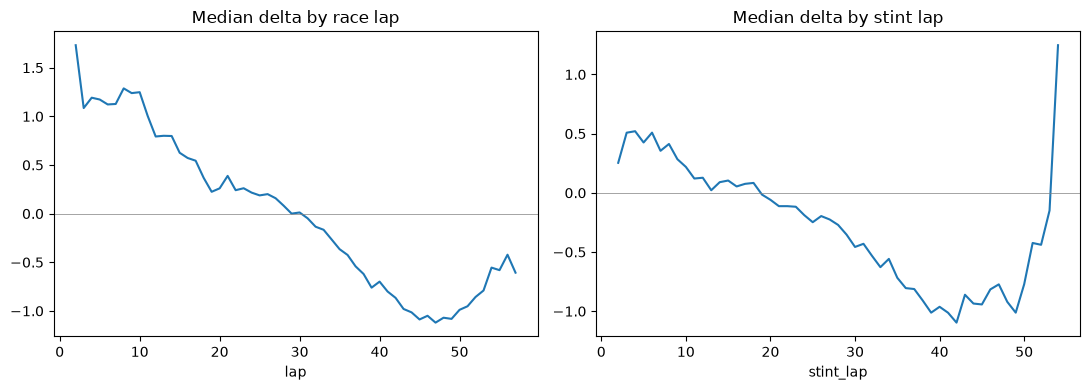

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
model_rows.groupby("lap")["delta"].median().plot(ax=ax[0], title="Median delta by race lap")
model_rows.groupby("stint_lap")["delta"].median().plot(ax=ax[1], title="Median delta by stint lap")
for a in ax: a.axhline(0, color="grey", lw=0.5)
plt.tight_layout(); plt.show()

In [10]:
long_laps = laps[laps["lap_time_seconds"] > 200]
print(long_laps.groupby(["season", "round", "lap"]).size())

season  round  lap
2023    3      8      17
               9       8
               54      3
               55     14
               56     11
               57     10
               58      2
2024    4      2      18
        5      27      1
dtype: int64


In [11]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error

laps["race"] = laps["season"].astype(str) + "-R" + laps["round"].astype(str)
laps["race_laps"] = laps.groupby("race")["lap"].transform("max")
laps["race_progress"] = laps["lap"] / laps["race_laps"]

model_rows = laps[laps["is_clean"] & laps["usable_ref"]].copy()
FEATURES = ["lap", "stint_lap", "race_progress"]
X, y, groups = model_rows[FEATURES], model_rows["delta"], model_rows["race"]

rows = []
for train_idx, test_idx in LeaveOneGroupOut().split(X, y, groups):
    model = Ridge(alpha=1.0).fit(X.iloc[train_idx], y.iloc[train_idx])
    pred = model.predict(X.iloc[test_idx])
    y_test = y.iloc[test_idx]
    rows.append({
        "race": groups.iloc[test_idx].iloc[0],
        "n": len(y_test),
        "mae_zero": mean_absolute_error(y_test, np.zeros(len(y_test))),
        "mae_ridge": mean_absolute_error(y_test, pred),
    })

results = pd.DataFrame(rows)
print(results.round(3))
print("overall zero :", ((results["mae_zero"] * results["n"]).sum() / results["n"].sum()).round(3))
print("overall ridge:", ((results["mae_ridge"] * results["n"]).sum() / results["n"].sum()).round(3))

      race     n  mae_zero  mae_ridge
0  2023-R1   919     0.926      0.652
1  2023-R2   829     0.875      0.513
2  2023-R3   741     0.800      0.637
3  2023-R4   840     0.779      0.423
4  2023-R5  1078     0.659      0.425
5  2024-R1  1024     0.902      0.527
6  2024-R2   811     0.936      0.617
7  2024-R3   865     0.763      0.553
8  2024-R4   774     1.129      0.679
9  2024-R5   770     0.861      0.680
overall zero : 0.857
overall ridge: 0.564
